# 3D SPILS-Net GNN Result Analysis

This notebook analyzes 3D surrogate model performance for SPILS-Net with Graph Neural Network (GNN) entry and exit layers on unstructured 2D interface node distributions in 3D elastoplastic domain simulations.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from mpl_toolkits.mplot3d import Axes3D  # Register 3D projection
from pathlib import Path

# Publication quality styling matching LaTeX / 2D analysis standards
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "savefig.dpi": 300,
    "figure.autolayout": False,
})

In [2]:
colors_ordered = [
    "tab:blue",
    "tab:orange",
    "tab:green",
    "tab:red",
    "tab:purple",
    "tab:brown",
    "tab:pink",
    "tab:cyan",
    "tab:olive"
]

internal_state_color = "tab:olive"

def make_plot_3d(ax, data, node_indices, dof_offset=0, n_dofs=3, linestyle='-', **kwargs):
    """
    Plots time-series data for specified node indices and DOF offset.
    
    Args:
        ax: Matplotlib axis.
        data: Array of shape [num_steps, num_nodes * n_dofs].
        node_indices: List of node indices to plot.
        dof_offset: DOF offset (0 for X, 1 for Y, 2 for Z).
        n_dofs: Number of DOFs per node (default 3 for 3D).
    """
    for i, node_idx in enumerate(node_indices):
        feature_idx = node_idx * n_dofs + dof_offset
        if feature_idx < data.shape[1]:
            ax.plot(
                data[:, feature_idx],
                linestyle=linestyle,
                color=colors_ordered[i % len(colors_ordered)],
                **kwargs
            )

## 1. Load Simulation Results & Mesh Topology

In [3]:
# Configuration matching the simulation run
law = "plastic"
method = "spils_net_gnn"
version = "v01"
freq = 1000

results_dir = Path("results_3d_disc")
topo_path = Path("training_data_3d_disc") / f"interface_topology_3d_disc_{law}.npz"

suffix_tct = f"3d_disc_{law}_f{freq}"
suffix_sm  = f"3d_disc_{law}_{method}_{version}_f{freq}"

# Load Full FEM Ground Truth Results (no if checks, will throw FileNotFoundError if missing)
tct_file_in       = results_dir / f"tct_results_in_{suffix_tct}.npy"
tct_file_out      = results_dir / f"tct_results_out_{suffix_tct}.npy"
tct_file_internal = results_dir / f"tct_results_internal_{suffix_tct}.npy"

tct_results_in  = np.load(tct_file_in)
tct_results_out = np.load(tct_file_out)
tct_results_internal = np.load(tct_file_internal)
has_true_data = True

# Load SM Prediction Results (no if checks)
sm_results_in       = np.load(results_dir / f"sm_results_in_{suffix_sm}.npy")
sm_results_out      = np.load(results_dir / f"sm_results_out_{suffix_sm}.npy")
sm_results_internal = np.load(results_dir / f"sm_results_internal_{suffix_sm}.npy")
sm_results_error    = np.load(results_dir / f"sm_results_error_{suffix_sm}.npy")

# Trim length matching
min_len = min(tct_results_in.shape[0], sm_results_in.shape[0], tct_results_out.shape[0], sm_results_out.shape[0], tct_results_internal.shape[0], sm_results_internal.shape[0])
tct_results_in       = tct_results_in[:min_len]
tct_results_out      = tct_results_out[:min_len]
tct_results_internal = tct_results_internal[:min_len]
sm_results_in        = sm_results_in[:min_len]
sm_results_out       = sm_results_out[:min_len]
sm_results_internal  = sm_results_internal[:min_len]
sm_results_error     = sm_results_error[:min_len]

# Load interface mesh topology
topo_data = np.load(topo_path)
node_coords = np.asarray(topo_data["coords"], dtype=float)
connectivity = np.asarray(topo_data["connectivity"], dtype=int)
num_nodes = node_coords.shape[0]

print(f"Loaded 3D Results for {method.upper()} ({law}, v{version}, {freq}Hz):")
print(f"  Displacements (In) shape : {sm_results_in.shape}")
print(f"  Forces (Out) shape        : {sm_results_out.shape}")
print(f"  Internal State shape      : {sm_results_internal.shape}")
print(f"  Relative Error shape      : {sm_results_error.shape}")
print(f"  Has Full FEM Ground Truth : {has_true_data}")
print(f"  FEM Internal State shape  : {tct_results_internal.shape}")
print(f"  Interface Nodes           : {num_nodes} nodes, {connectivity.shape[0]} triangular faces")


Loaded 3D Results for SPILS_NET_GNN (plastic, vv01, 1000Hz):
  Displacements (In) shape : (2000, 918)
  Forces (Out) shape        : (2000, 306)
  Internal State shape      : (2000,)
  Relative Error shape      : (2000,)
  Has Full FEM Ground Truth : True
  FEM Internal State shape  : (2000,)
  Interface Nodes           : 102 nodes, 150 triangular faces


## 2. 3D Unstructured Interface Mesh Topology Visualization

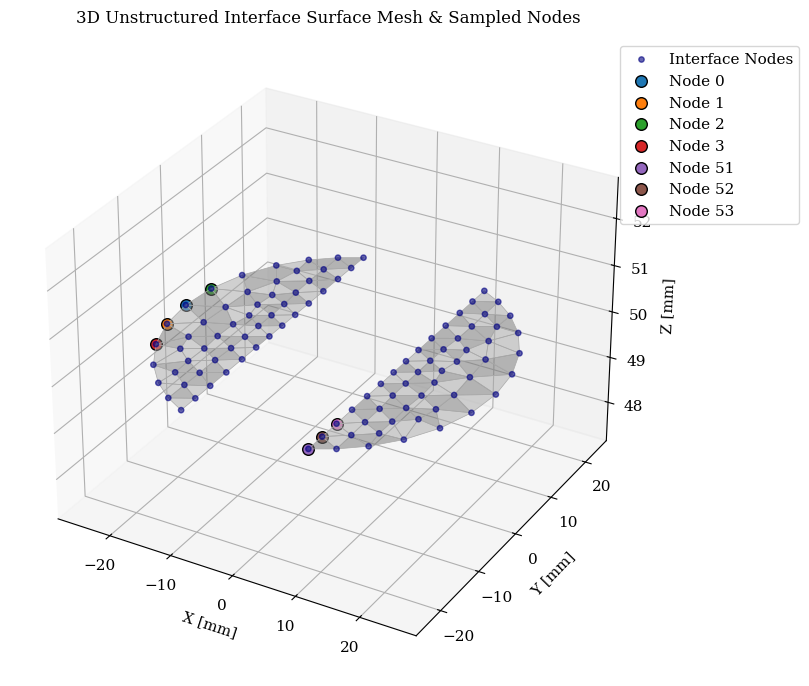

In [4]:
# Sample representative interface nodes distributed across the 3D surface
# Sample representative interface nodes distributed across the 3D surface
left_idxs = np.where(node_coords[:, 0] < 0)[0]
right_idxs = np.where(node_coords[:, 0] > 0)[0]
sample_nodes = list(left_idxs[:4]) + list(right_idxs[:3])
sample_nodes = [n for n in sample_nodes if n < num_nodes]

if node_coords is not None and connectivity is not None:
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection='3d')
    
    tri_conn = np.asarray(connectivity, dtype=int)
    x_c, y_c, z_c = node_coords[:, 0].astype(float), node_coords[:, 1].astype(float), node_coords[:, 2].astype(float)
    
    # Plot triangular surface mesh
    ax.plot_trisurf(x_c, y_c, z_c, triangles=tri_conn, color='gainsboro', edgecolor='darkgray', alpha=0.5, linewidth=0.5)
    
    # Plot all interface nodes
    ax.scatter(x_c, y_c, z_c, color='navy', s=15, alpha=0.6, label='Interface Nodes')
    
    # Highlight sampled nodes
    for i, idx in enumerate(sample_nodes):
        c = colors_ordered[i % len(colors_ordered)]
        ax.scatter(x_c[idx], y_c[idx], z_c[idx], color=c, s=70, edgecolor='k', zorder=10, label=f'Node {idx}')
    
    ax.set_title("3D Unstructured Interface Surface Mesh & Sampled Nodes", fontsize=12, pad=12)
    ax.set_xlabel("X [mm]")
    ax.set_ylabel("Y [mm]")
    ax.set_zlabel("Z [mm]")
    ax.legend(loc='upper right', bbox_to_anchor=(1.25, 1.0))
    plt.tight_layout()
    Path("figures").mkdir(exist_ok=True)
    plt.savefig("figures/3d_interface_topology.pdf", format="pdf", bbox_inches="tight")
    plt.show()

## 3. Overlapped 3D Response Comparison Plot (Full FEM vs SPILS-Net GNN Prediction)

This figure overlaps the **Full FEM reference ground truth** (solid, semi-transparent background track) with the **SPILS-Net GNN prediction** (dashed overlay), demonstrating close agreement across 3D displacements, nodal forces, and internal plasticity evolution.

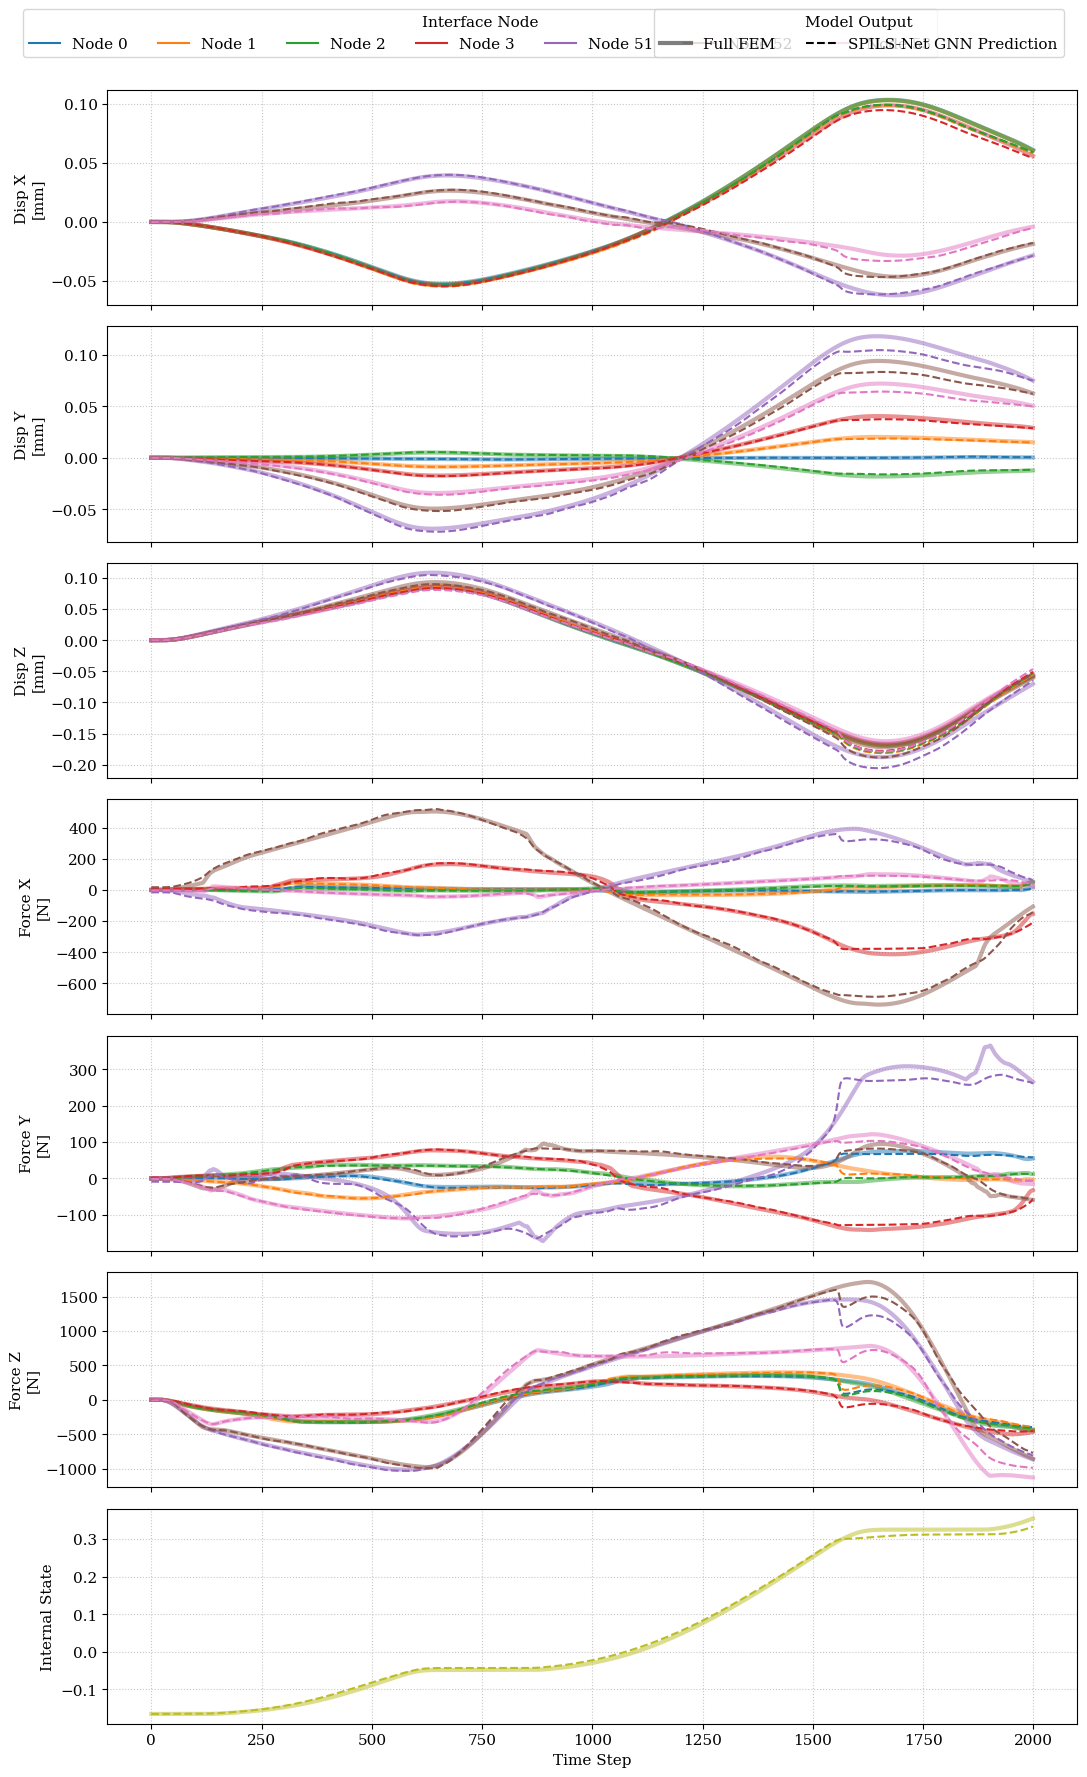

In [5]:
show_predictions = True

fig, axs = plt.subplots(7, 1, figsize=(11, 18), sharex=True)

# Subplot Y-labels
axs[0].set_ylabel('Disp X\n[mm]')
axs[1].set_ylabel('Disp Y\n[mm]')
axs[2].set_ylabel('Disp Z\n[mm]')
axs[3].set_ylabel('Force X\n[N]')
axs[4].set_ylabel('Force Y\n[N]')
axs[5].set_ylabel('Force Z\n[N]')
axs[6].set_ylabel('Internal State')
axs[6].set_xlabel("Time Step")

# --- 1. Plot TRUE FULL FEM Data (Thicker, semi-transparent background track) ---
make_plot_3d(axs[0], tct_results_in, sample_nodes, dof_offset=0, linewidth=3, alpha=0.5)
make_plot_3d(axs[1], tct_results_in, sample_nodes, dof_offset=1, linewidth=3, alpha=0.5)
make_plot_3d(axs[2], tct_results_in, sample_nodes, dof_offset=2, linewidth=3, alpha=0.5)
make_plot_3d(axs[3], tct_results_out, sample_nodes, dof_offset=0, linewidth=3, alpha=0.5)
make_plot_3d(axs[4], tct_results_out, sample_nodes, dof_offset=1, linewidth=3, alpha=0.5)
make_plot_3d(axs[5], tct_results_out, sample_nodes, dof_offset=2, linewidth=3, alpha=0.5)
axs[6].plot(tct_results_internal, linewidth=3, alpha=0.5, color=internal_state_color)

# --- 2. Plot PREDICTED Data (Thinner, dashed overlay) ---
if show_predictions:
    make_plot_3d(axs[0], sm_results_in, sample_nodes, dof_offset=0, linestyle='--', linewidth=1.5)
    make_plot_3d(axs[1], sm_results_in, sample_nodes, dof_offset=1, linestyle='--', linewidth=1.5)
    make_plot_3d(axs[2], sm_results_in, sample_nodes, dof_offset=2, linestyle='--', linewidth=1.5)
    make_plot_3d(axs[3], sm_results_out, sample_nodes, dof_offset=0, linestyle='--', linewidth=1.5)
    make_plot_3d(axs[4], sm_results_out, sample_nodes, dof_offset=1, linestyle='--', linewidth=1.5)
    make_plot_3d(axs[5], sm_results_out, sample_nodes, dof_offset=2, linestyle='--', linewidth=1.5)
    axs[6].plot(sm_results_internal, linestyle='--', linewidth=1.5, color=internal_state_color)

# Grid formatting
for ax in axs.flat:
    ax.grid(True, linestyle=':', alpha=0.7)

# Legend 1: Node Location Handles
location_handles = [
    mlines.Line2D([], [], color=colors_ordered[i % len(colors_ordered)], label=f"Node {idx}")
    for i, idx in enumerate(sample_nodes)
]

# Legend 2: Model Output Style Handles (Full FEM vs SPILS-Net GNN Prediction)
style_handles = [
    mlines.Line2D([], [], color="k", label="Full FEM", linewidth=3, alpha=0.5),
    mlines.Line2D([], [], color="k", label="SPILS-Net GNN Prediction", linestyle="--", linewidth=1.5),
]

# Location legend top-left
fig.legend(
    handles=location_handles,
    loc="upper left",
    title="Interface Node",
    ncol=len(sample_nodes),
    bbox_to_anchor=(0.02, 0.99)
)

# Model style legend top-right
fig.legend(
    handles=style_handles,
    loc="upper right",
    title="Model Output",
    ncol=2,
    bbox_to_anchor=(0.98, 0.99)
)

fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.95))
plt.savefig(f"figures/06_{method}_3d_results_{freq}.pdf", format="pdf", bbox_inches="tight", pad_inches=0.05)
plt.show()

## 4. Relative Nodal Error Evolution ($e_n$ Over Time)

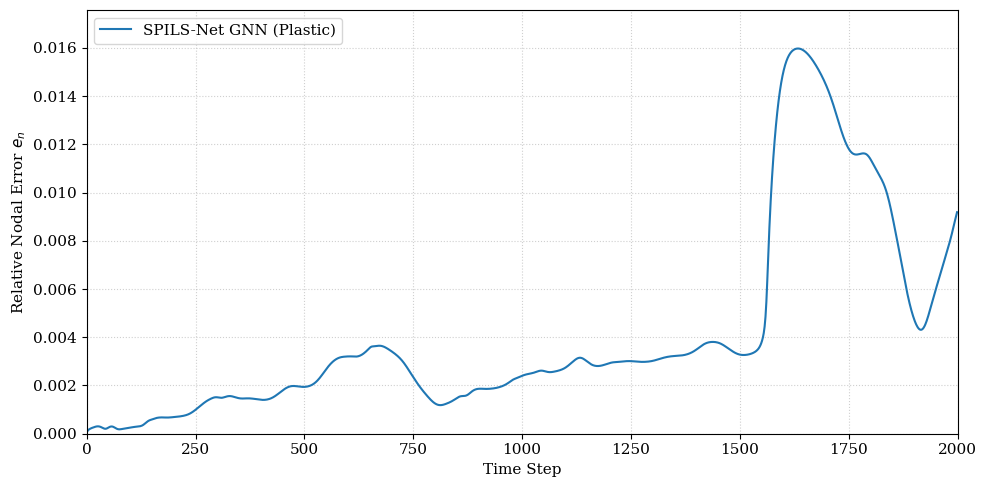

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))

time_steps = len(sm_results_error)
ax.plot(sm_results_error, color="tab:blue", label=f"SPILS-Net GNN ({law.capitalize()})", linewidth=1.5)

ax.set_xlabel("Time Step")
ax.set_ylabel("Relative Nodal Error $e_n$")
ax.set_xlim(0, time_steps)
ax.set_ylim(0, max(np.max(sm_results_error) * 1.1, 0.01))
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc="upper left", frameon=True)

fig.tight_layout()
plt.savefig(f"figures/06_3d_{law}_error_evolution_{freq}.pdf", format="pdf", bbox_inches="tight", pad_inches=0.05)
plt.show()

## 5. Summary Performance Statistics

In [7]:
mean_error = np.mean(sm_results_error)
max_error  = np.max(sm_results_error)
final_error = sm_results_error[-1]

# Global Relative Error calculation (matching create_predictor_3d.py evaluate_model)
if has_true_data:
    global_err = np.linalg.norm(tct_results_out - sm_results_out) / max(np.linalg.norm(tct_results_out), 1e-10)
else:
    global_err = None

print("=" * 60)
print(f"  3D SPILS-Net GNN Performance Summary ({law.capitalize()}, {freq}Hz)")
print("=" * 60)
if global_err is not None:
    print(f"  Global Relative Error       : {global_err * 100:.4f}%")
print(f"  Mean Relative Error (e_n)   : {mean_error * 100:.4f}%")
print(f"  Max Relative Error (e_n)    : {max_error * 100:.4f}%")
print(f"  Final Step Error (e_n)      : {final_error * 100:.4f}%")
print(f"  Total Simulation Time Steps : {time_steps}")
print("=" * 60)


  3D SPILS-Net GNN Performance Summary (Plastic, 1000Hz)
  Global Relative Error       : 8.5470%
  Mean Relative Error (e_n)   : 0.4076%
  Max Relative Error (e_n)    : 1.5975%
  Final Step Error (e_n)      : 0.9188%
  Total Simulation Time Steps : 2000
